# Case 05 — Customer Segmentation

Segmentação acionável para CRM, cross-sell, retenção e relacionamento. A taxonomia é formada sem outcomes futuros, congelada em 2026Q1 e aplicada sem refit em 2026Q2–Q3.

## 1. Decisão, unidade e fronteira temporal

**Unidade:** `customer_id × snapshot_quarter`.  **Decision timestamp:** fechamento de cada trimestre.  **Desenvolvimento:** 2026Q1. **Validação temporal:** 2026Q2. **Holdout:** 2026Q3.  **Regra de leakage:** receita, margem, churn e adoção nos 90 dias seguintes não entram em nenhuma decisão de clusterização.

In [1]:
from pathlib import Path
import json, pandas as pd
from IPython.display import display, Image, Markdown
ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
display(json.loads((ROOT/'outputs/metrics/data_audit.json').read_text(encoding='utf-8')))

{'rows': 900000,
 'columns': 52,
 'unique_customers': 300000,
 'quarters': ['2026Q1', '2026Q2', '2026Q3'],
 'duplicate_rows': 0,
 'duplicate_customer_quarter': 0,
 'customers_with_three_snapshots': 300000,
 'future_outcomes_excluded_from_clustering': ['revenue_next_90d',
  'margin_next_90d',
  'churn_next_90d',
  'product_adoption_next_90d']}

## 2. Data quality, escala e redundância

**Comentário Técnico:** zero é preservado como valor legítimo. A ausência de `credit_utilization` é estrutural para clientes sem cartão e recebe indicador próprio. O código sentinela `9999` em login é convertido em missing antes da imputação. Caudas são winsorizadas e transformadas somente com parâmetros aprendidos em 2026Q1.

,snapshot_quarter,rows,customers,credit_utilization_missing,push_missing,email_missing,login_sentinel_9999
0,2026Q1,300000,300000,0.465337,0.024010,0.033643,0.006053
1,2026Q2,300000,300000,0.460103,0.037717,0.042443,0.009153
2,2026Q3,300000,300000,0.453980,0.052973,0.051740,0.012003


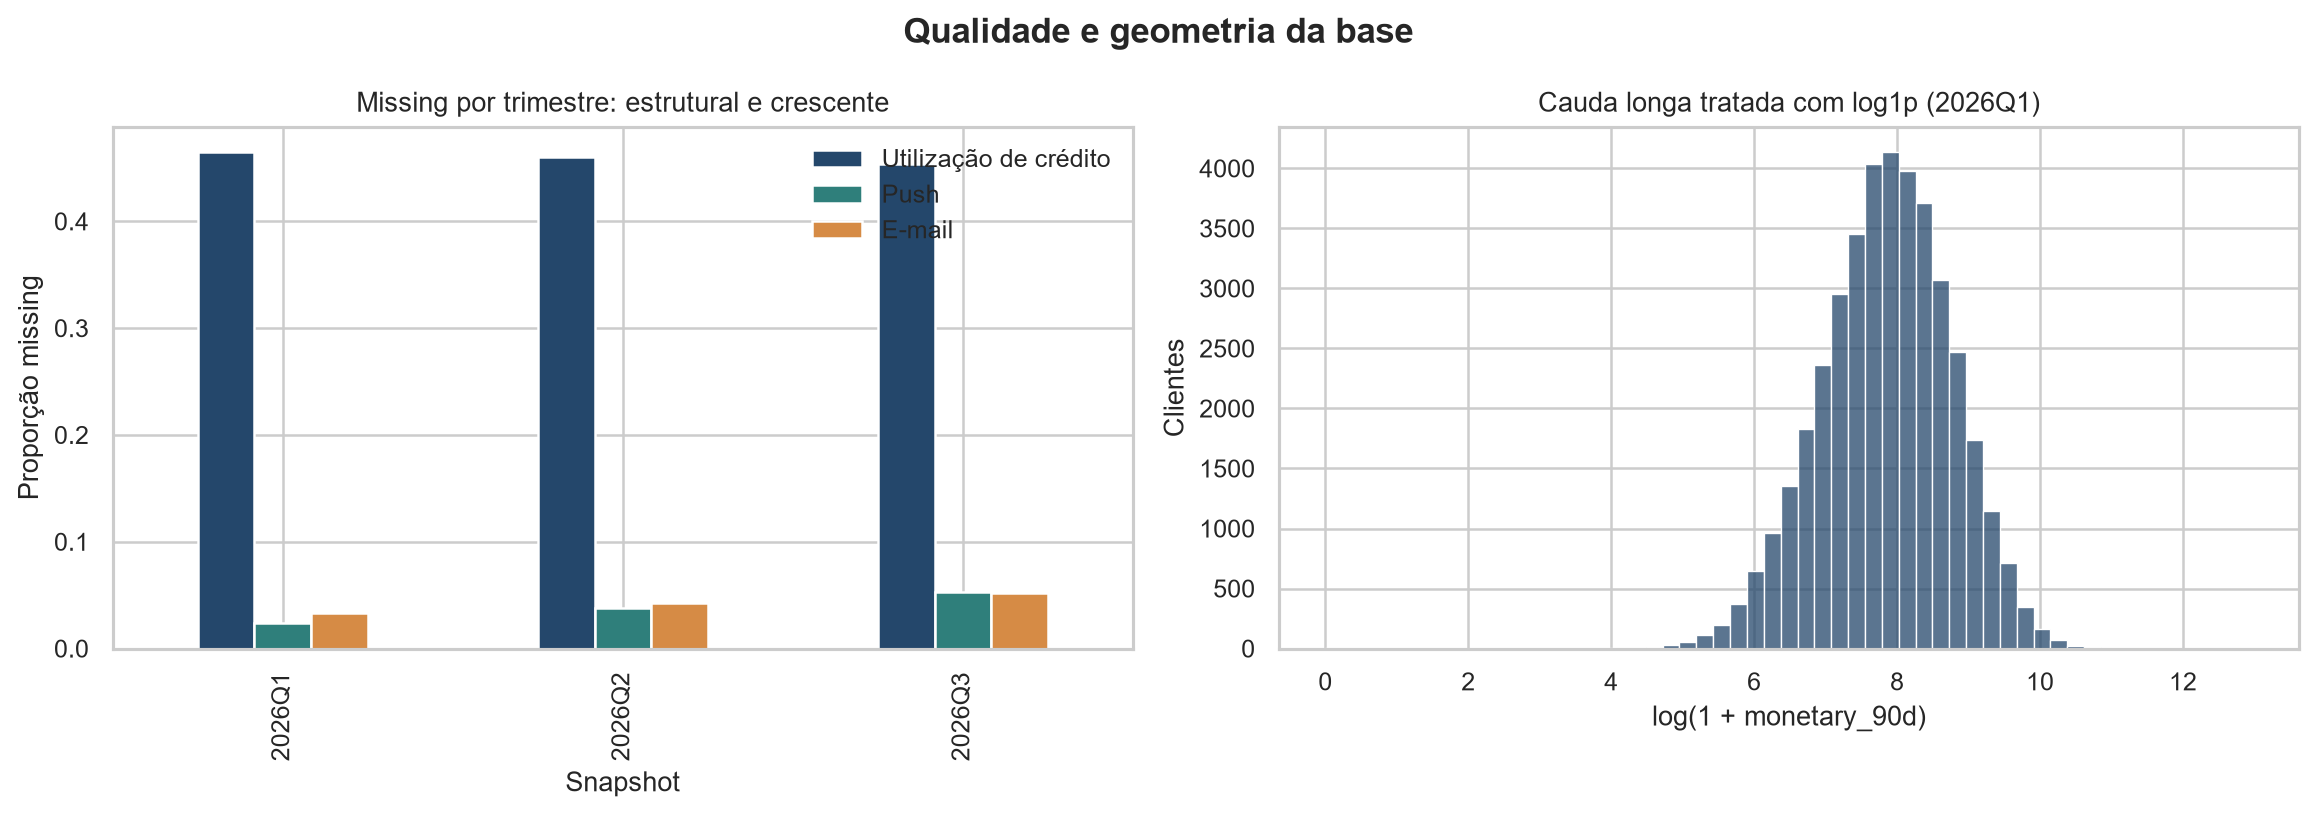

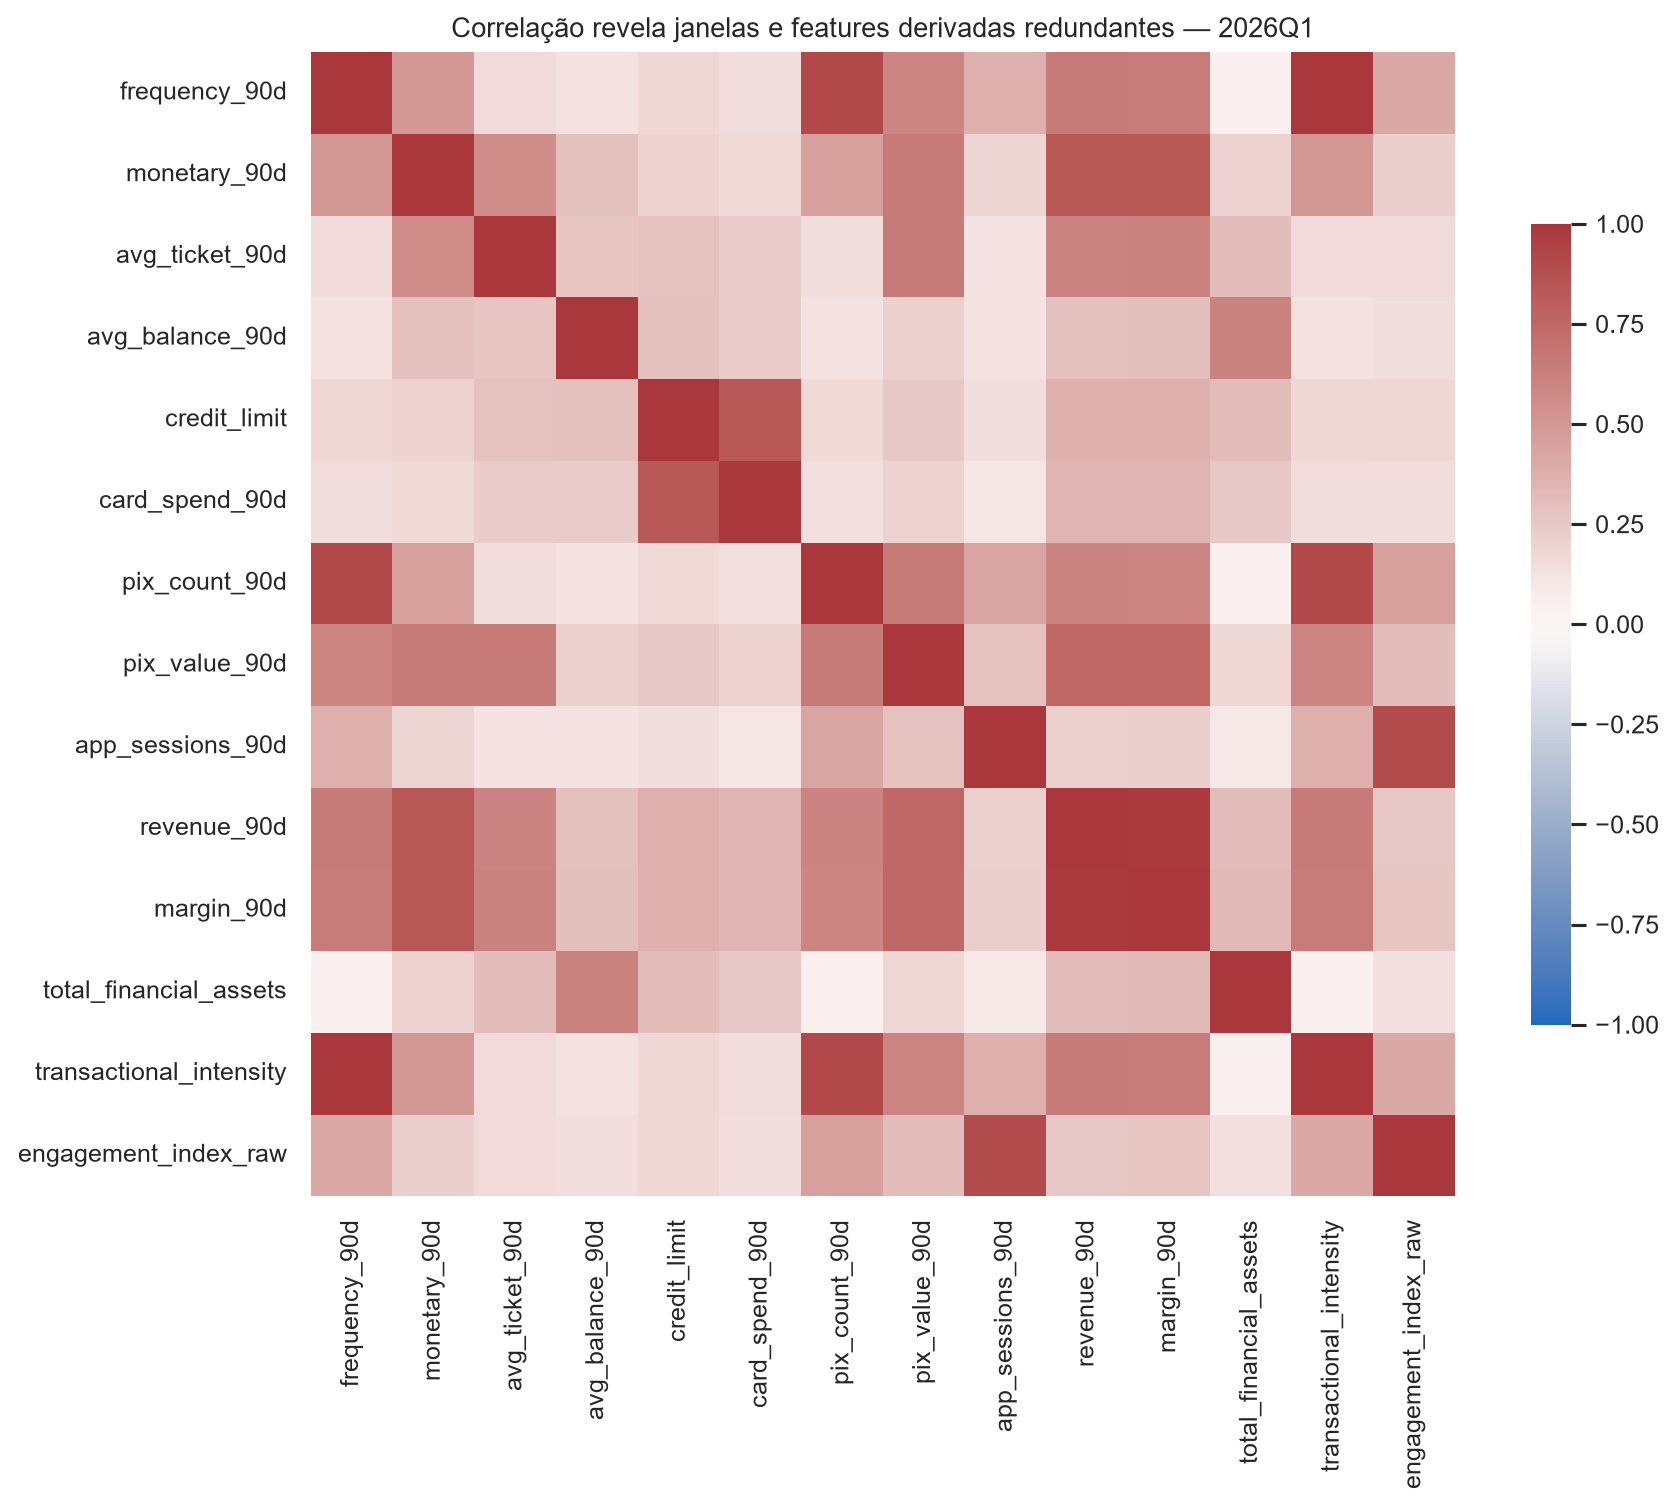

In [2]:
display(pd.read_csv(ROOT/'outputs/tables/data_quality_by_quarter.csv'))
display(Image(filename=str(ROOT/'outputs/figures/01_data_quality_and_scale.png')))
display(Image(filename=str(ROOT/'outputs/figures/02_feature_correlation.png')))

## 3. Baseline RFM e benchmark não supervisionado

A baseline RFM é útil por transparência, mas reduz o relacionamento a três dimensões. Os challengers são comparados com amostragem explícita nas métricas quadráticas. Hierarchical e HDBSCAN são diagnósticos quando não oferecem scoring operacional direto.

,candidate,algorithm,preprocessing,n_clusters,fit_rows,scope,status,min_cluster_share,silhouette,davies_bouldin,calinski_harabasz,noise_share
0,KMeans_Robust_k4,MiniBatchKMeans,log+winsor+RobustScaler,4.0,300000,full development,evaluated,0.146917,0.238349,1.524494,3105.728644,NaN
1,KMeans_Robust_k5,MiniBatchKMeans,log+winsor+RobustScaler,5.0,300000,full development,evaluated,0.005177,0.206473,1.717694,2351.935732,NaN
2,KMeans_Robust_k6,MiniBatchKMeans,log+winsor+RobustScaler,6.0,300000,full development,evaluated,0.027650,0.195367,1.745500,2312.140913,NaN
3,KMeans_Robust_k7,MiniBatchKMeans,log+winsor+RobustScaler,7.0,300000,full development,evaluated,0.004197,0.177597,1.906762,1919.648511,NaN
4,KMeans_Standard_k6,MiniBatchKMeans,log+winsor+StandardScaler,6.0,300000,full development,evaluated,0.124103,0.100953,2.565703,527.383422,NaN
5,KMeans_Robust_PCA90_k6,MiniBatchKMeans,robust+PCA(11 comps),6.0,300000,full development,evaluated,0.027650,0.243314,1.466586,3278.145297,NaN
6,GMM_diag_Robust_k5,GaussianMixture,log+winsor+RobustScaler,5.0,60000,representative sample,evaluated,0.027400,0.221399,1.460459,2494.962739,NaN
7,GMM_diag_Robust_k6,GaussianMixture,log+winsor+RobustScaler,6.0,60000,representative sample,evaluated,0.012400,0.191428,2.871596,2100.166557,NaN
8,Hierarchical_Ward_k6,AgglomerativeClustering,log+winsor+RobustScaler,6.0,8000,diagnostic sample; no native scoring,evaluated,0.027250,0.235890,1.483852,2270.161796,NaN
9,HDBSCAN_Robust,HDBSCAN,log+winsor+RobustScaler,NaN,0,optional dependency,skipped: package unavailable,NaN,NaN,NaN,NaN,NaN


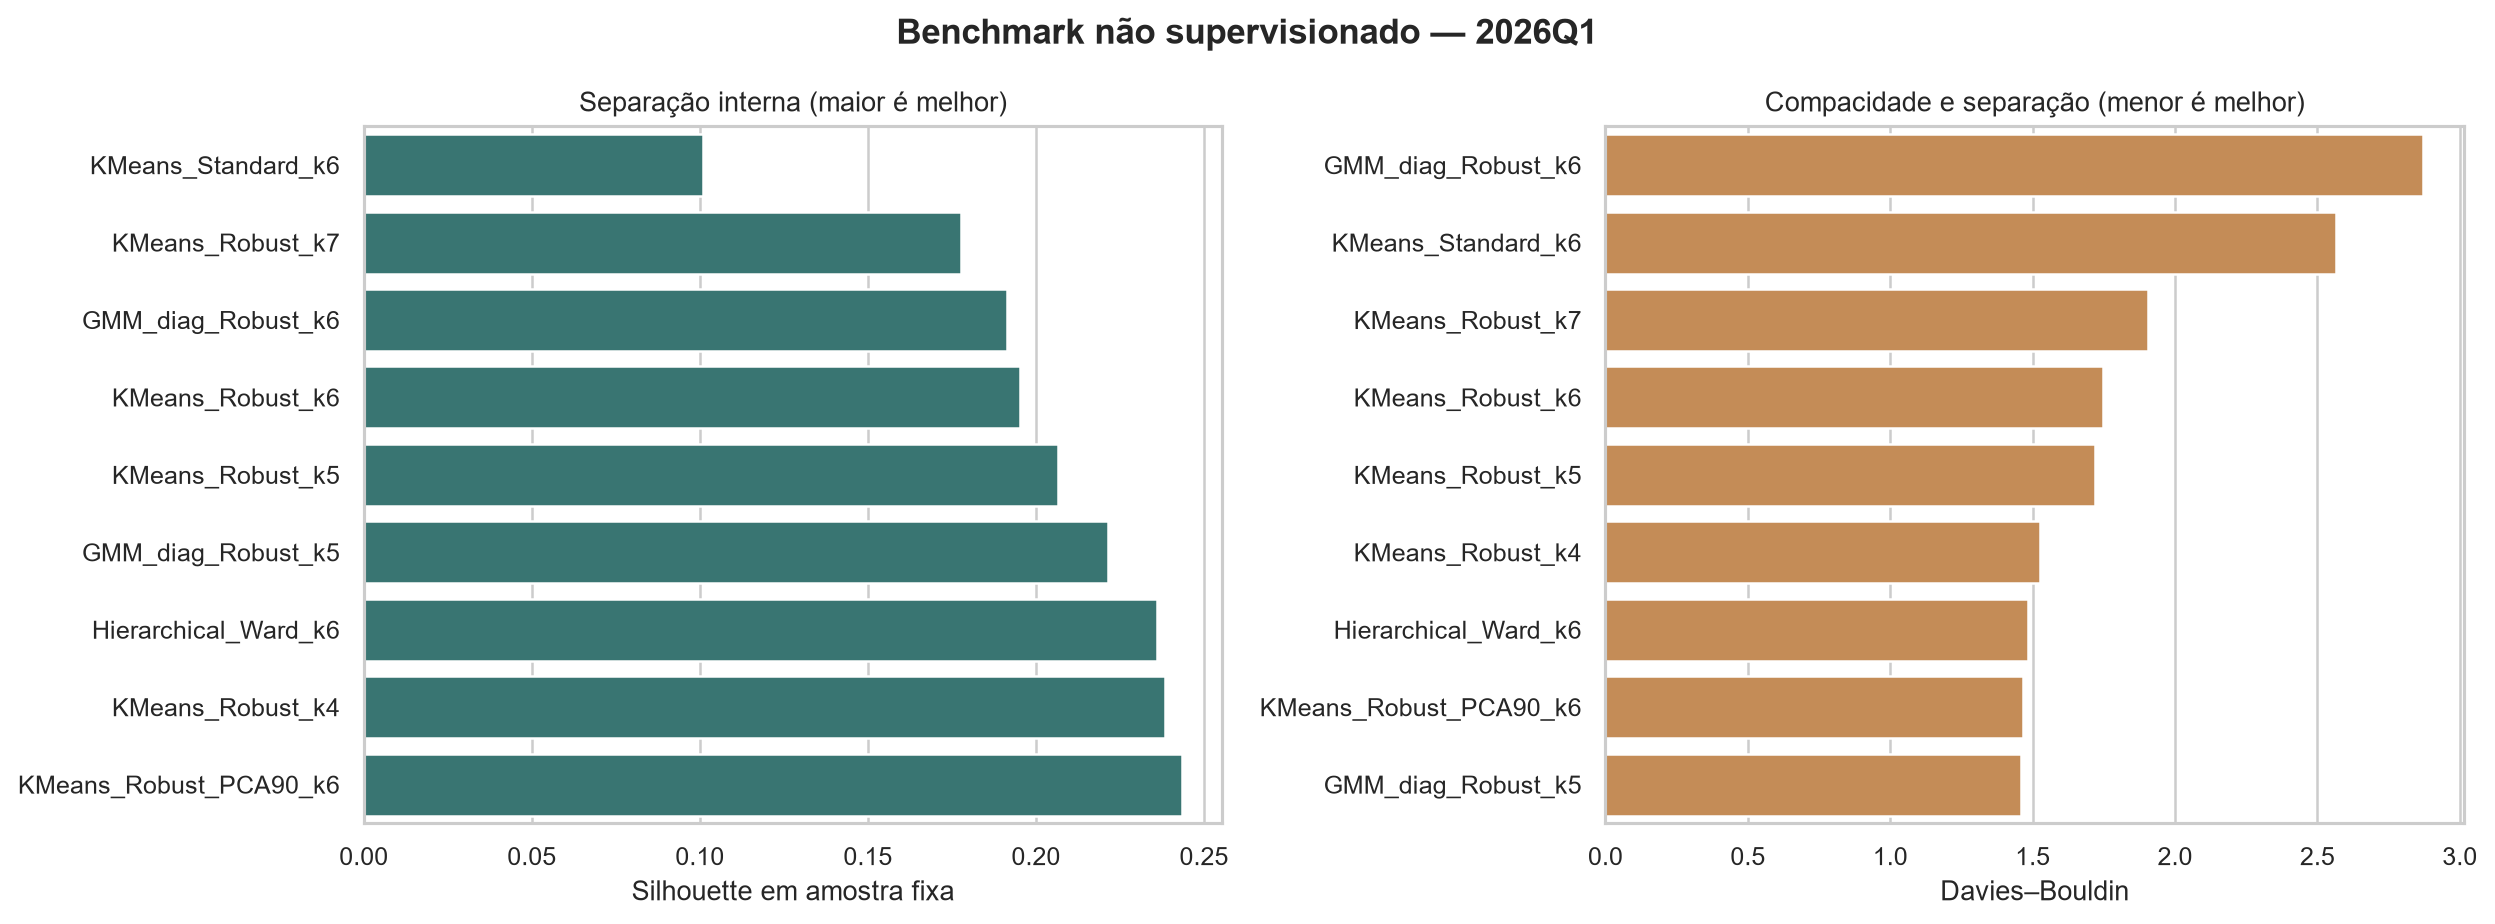

In [3]:
bench = pd.read_csv(ROOT/'outputs/metrics/internal_model_benchmark.csv')
display(bench)
display(Image(filename=str(ROOT/'outputs/figures/03_internal_benchmark.png')))

## 4. Congelamento do champion e perfis

O champion foi congelado como **KMeans_Robust_k6**, com seis segmentos. A escolha equilibra separação, escala mínima, capacidade de scoring, estabilidade e interpretabilidade; não maximiza isoladamente Silhouette.

{'freeze_timestamp_stage': 'before Q2/Q3 future-outcome inspection',
 'development_quarter': '2026Q1',
 'validation_quarter': '2026Q2',
 'holdout_quarter': '2026Q3',
 'champion': 'KMeans_Robust_k6',
 'n_clusters': 6,
 'feature_count_before_missing_indicators': 35,
 'future_outcomes_excluded': ['revenue_next_90d',
  'margin_next_90d',
  'churn_next_90d',
  'product_adoption_next_90d'],
 'selection_evidence': {'silhouette': 0.19536711275577545,
  'davies_bouldin': 1.7454999713720756,
  'minimum_cluster_share': 0.02765},
 'rationale': 'Six robust K-Means segments balance separation, minimum operational scale, native out-of-sample scoring, explainable centroids, and stable business profiles. PCA was not selected because its modest geometric benefit did not offset lost interpretability; hierarchical and density approaches remained diagnostic samples.',
 'cluster_name_map': {'4': 'Comerciantes Ativos',
  '2': 'Patrimônio & Valor',
  '0': 'Crédito Intensivo',
  '1': 'Digitais Engajados',
  '3

,cluster_id,segment_name,recency_days,frequency_90d,monetary_90d,avg_balance_90d,credit_utilization,card_spend_90d,pix_count_90d,merchant_txn_count_90d,merchant_gmv_90d,investment_balance,number_of_products,app_sessions_90d,campaign_click_rate_90d,revenue_90d,margin_90d,customers,share
0,0,Crédito Intensivo,6.602907,48.540386,7575.018457,3167.915108,0.412756,1109.487680,18.665539,74.893460,11468.532072,0.000000,1.648044,28.167691,0.153842,319.938004,166.890445,35780,0.119267
1,1,Digitais Engajados,7.539018,27.965610,3831.278867,3094.955622,0.413377,1061.420457,10.313142,0.000000,0.000000,0.000000,1.127482,32.618874,0.162945,119.567693,61.738692,118087,0.393623
2,2,Patrimônio & Valor,7.808539,27.601689,5824.117580,8164.730787,0.396924,1930.956924,10.106694,0.000000,0.000000,27046.350325,2.197341,32.036910,0.164497,221.715464,122.335928,31970,0.106567
3,3,Baixo Engajamento,13.169033,14.204617,1181.781009,1077.193379,0.386197,268.624287,4.476115,0.000000,0.000000,0.015860,0.597811,15.069771,0.132665,37.376852,18.601860,83043,0.276810
4,4,Comerciantes Ativos,6.510066,49.499699,8253.764608,3727.062870,0.407760,1228.019506,18.975045,74.959735,12055.517931,3108.727174,2.674141,28.411212,0.154486,346.676937,181.832206,8295,0.027650
5,5,Relacionamento Essencial,8.686572,24.562147,2723.166290,1961.687853,0.401460,670.178993,8.837415,0.000000,0.000000,2043.158049,1.912289,29.394567,0.155864,87.656106,44.884149,22825,0.076083


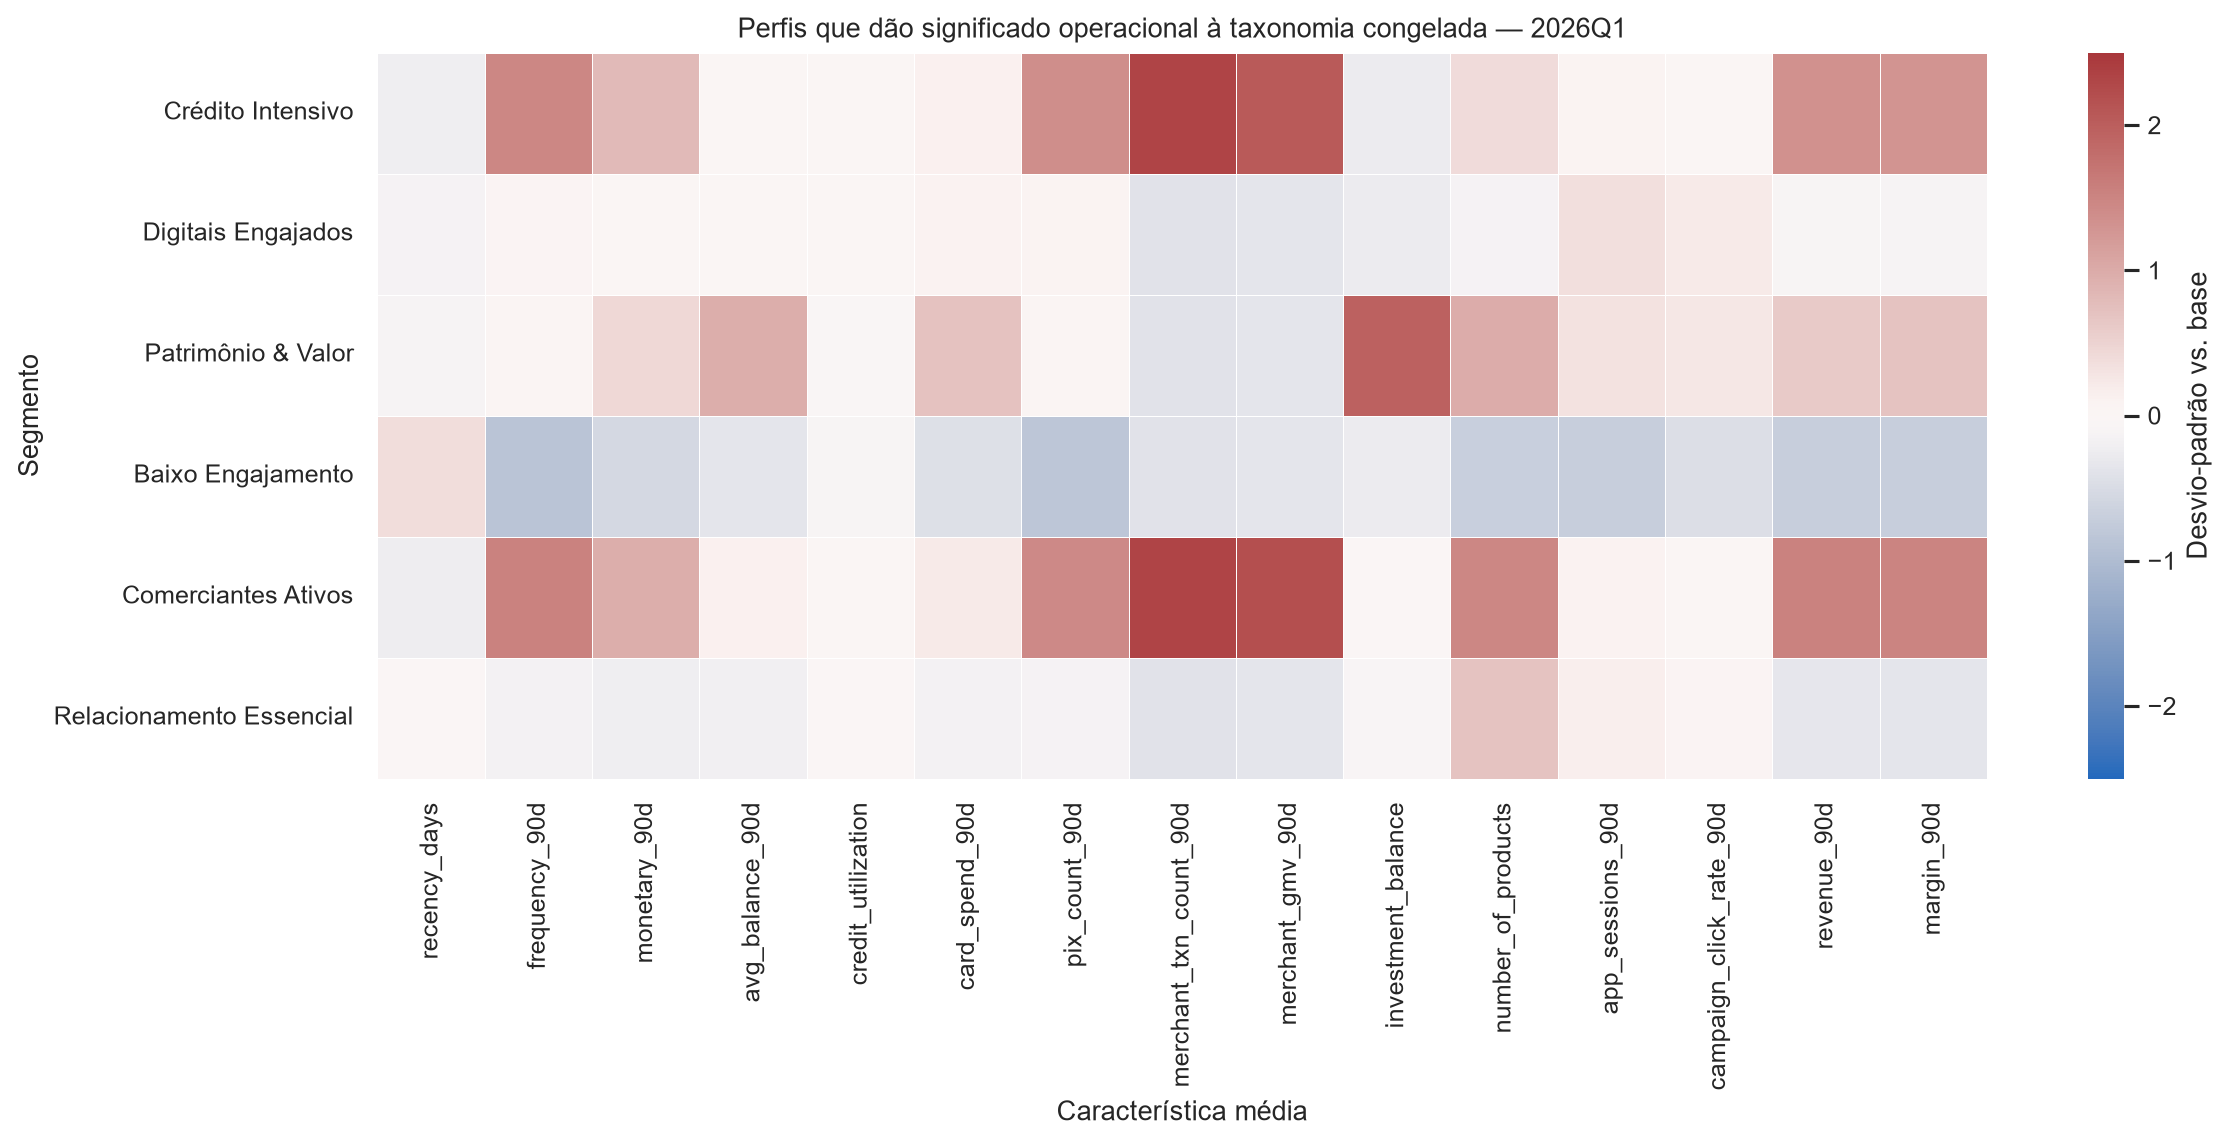

In [4]:
freeze = json.loads((ROOT/'outputs/metrics/taxonomy_freeze_record.json').read_text(encoding='utf-8'))
display(freeze)
display(pd.read_csv(ROOT/'outputs/tables/frozen_segment_profiles_q1.csv'))
display(Image(filename=str(ROOT/'outputs/figures/04_frozen_segment_profiles.png')))

## 5. Estabilidade temporal

O pipeline e os centroides de 2026Q1 são aplicados sem refit. Mudança de rótulo pode representar evolução real do cliente ou sensibilidade de fronteira; por isso são lidos em conjunto share, retenção, ARI/NMI e drift de centroide.

,from_quarter,to_quarter,label_retention,adjusted_rand_index,normalized_mutual_information
0,2026Q1,2026Q2,0.618610,0.308237,0.399753
1,2026Q2,2026Q3,0.621543,0.312670,0.405133
2,2026Q1,2026Q3,0.618930,0.309220,0.402236


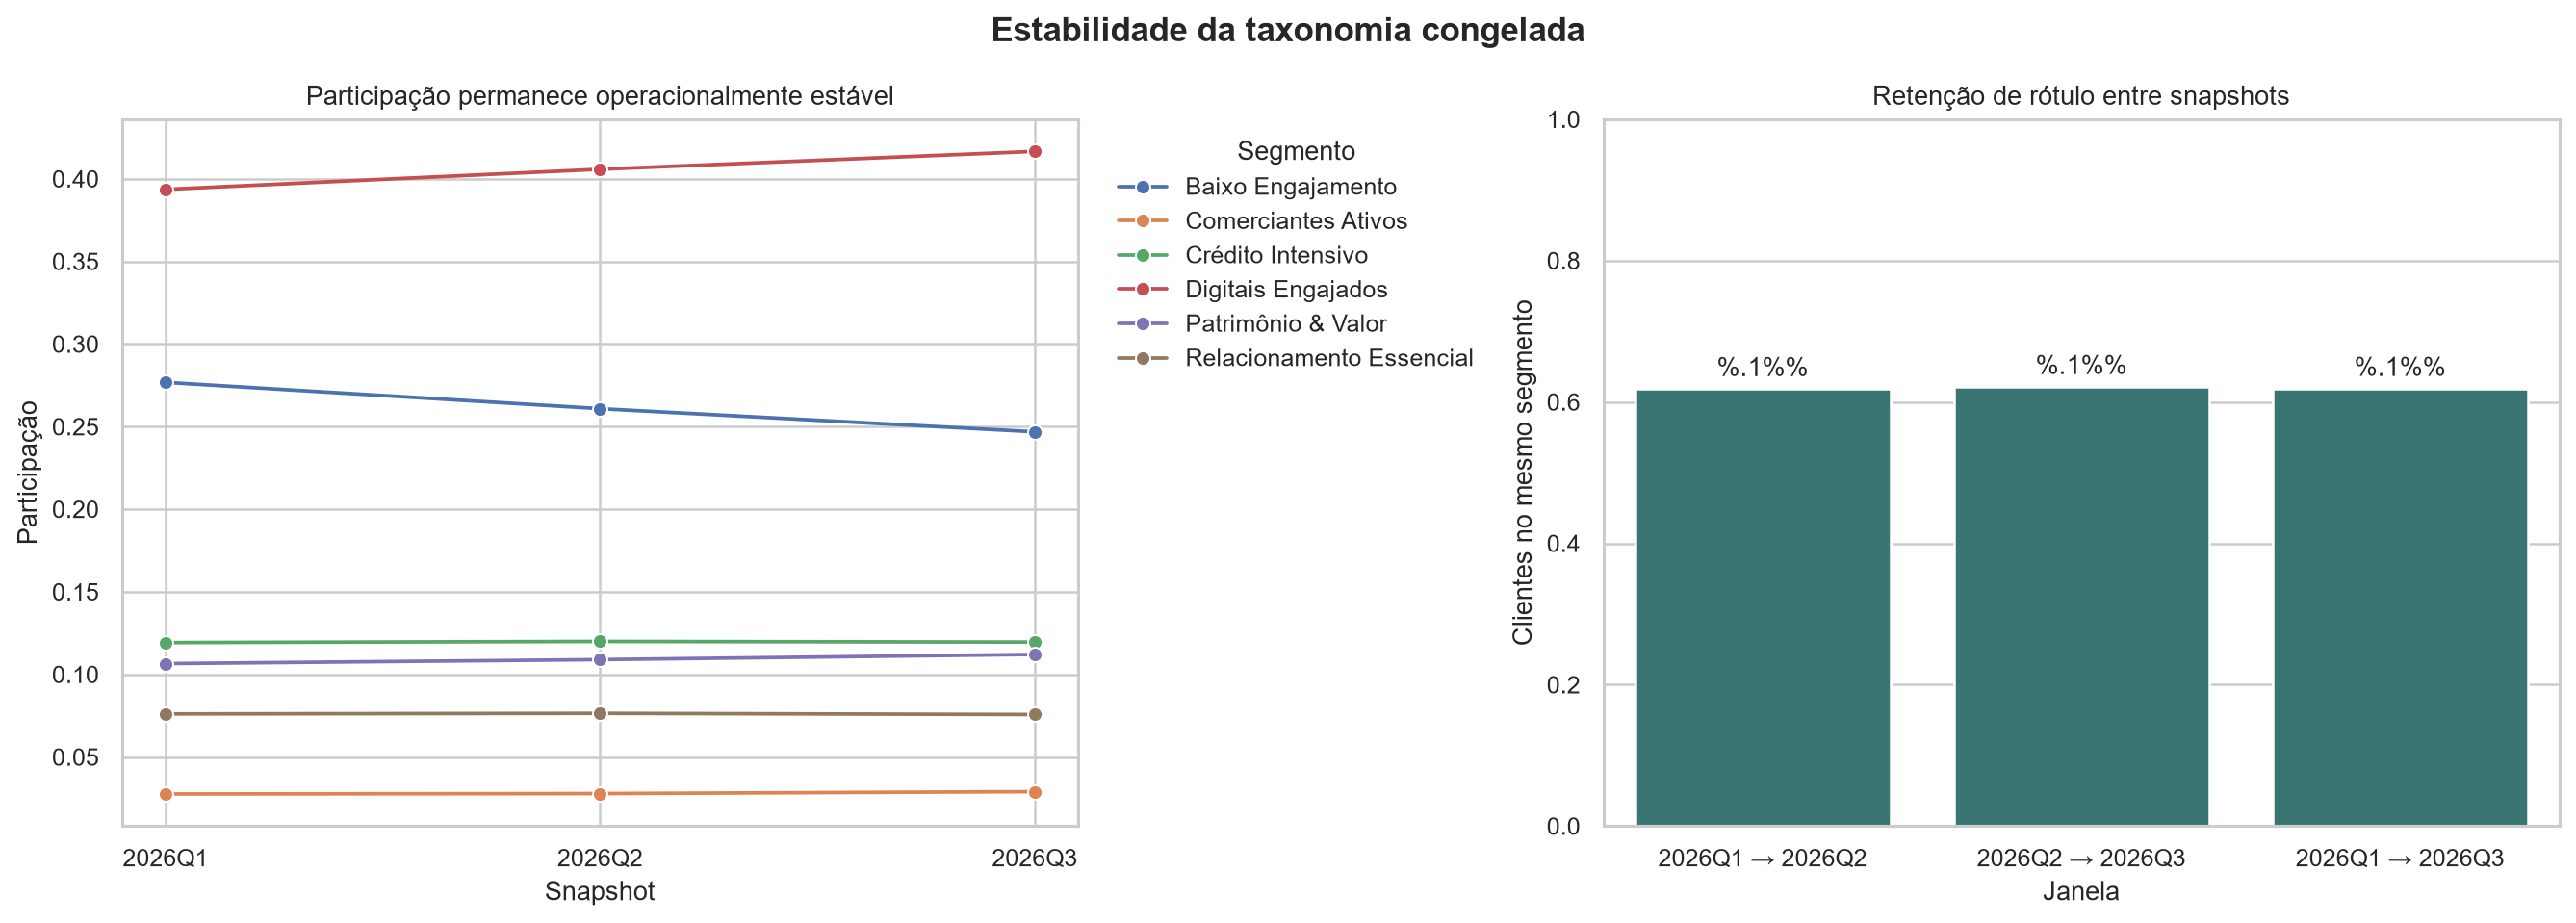

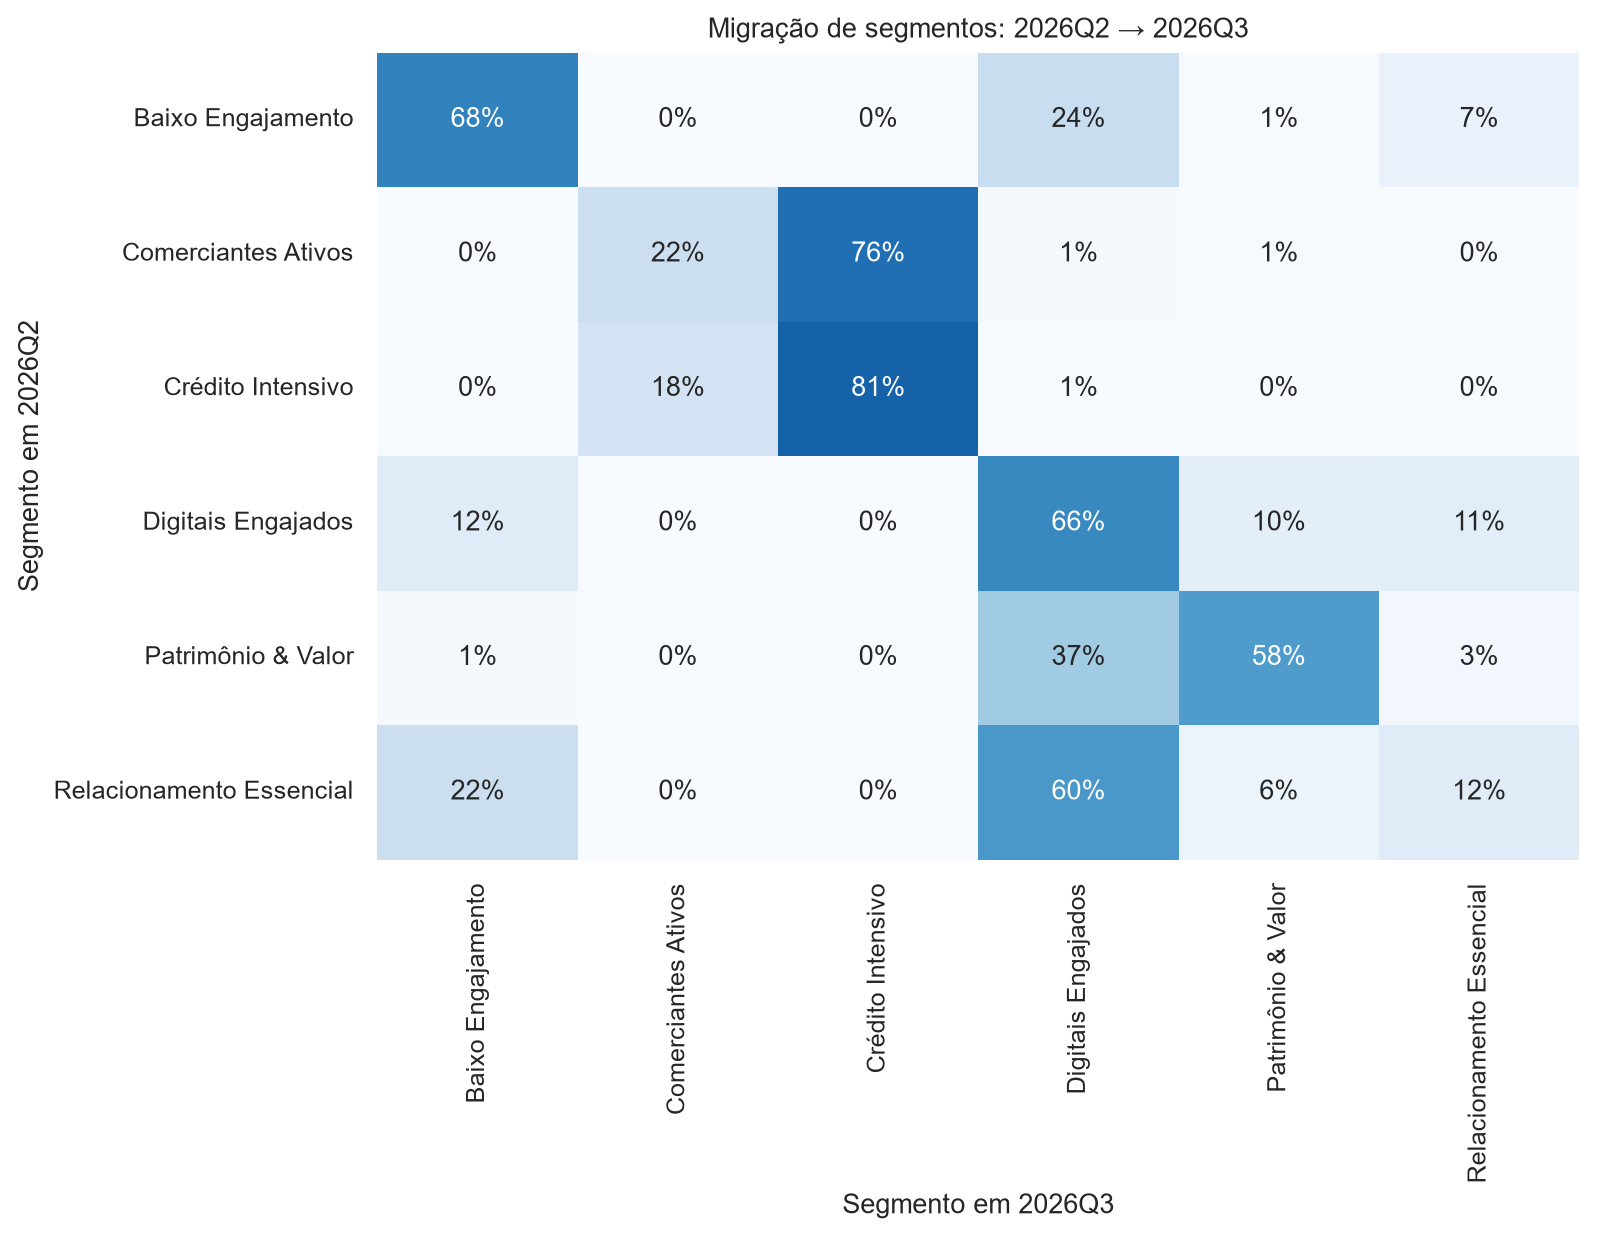

In [5]:
display(pd.read_csv(ROOT/'outputs/metrics/temporal_stability_metrics.csv'))
display(Image(filename=str(ROOT/'outputs/figures/05_temporal_stability.png')))
display(Image(filename=str(ROOT/'outputs/figures/06_migration_matrix.png')))

## 6. Validação externa pós-congelamento

**Análise/Interpretação:** outcomes futuros avaliam utilidade, não formam clusters. Diferenças de receita, margem, churn e adoção mostram diferenciação prospectiva, mas permanecem associativas.

,segment_name,customers,revenue_next_90d,margin_next_90d,churn_next_90d,product_adoption_next_90d
12,Baixo Engajamento,74065,41.026329,20.030291,0.090772,0.115129
13,Comerciantes Ativos,8719,456.596393,235.614291,0.037504,0.160110
14,Crédito Intensivo,35873,405.945290,208.291496,0.044908,0.177153
15,Digitais Engajados,124990,143.429410,72.654781,0.055564,0.192495
16,Patrimônio & Valor,33634,279.447563,151.218656,0.047274,0.192514
17,Relacionamento Essencial,22719,106.335330,53.342177,0.057001,0.160879


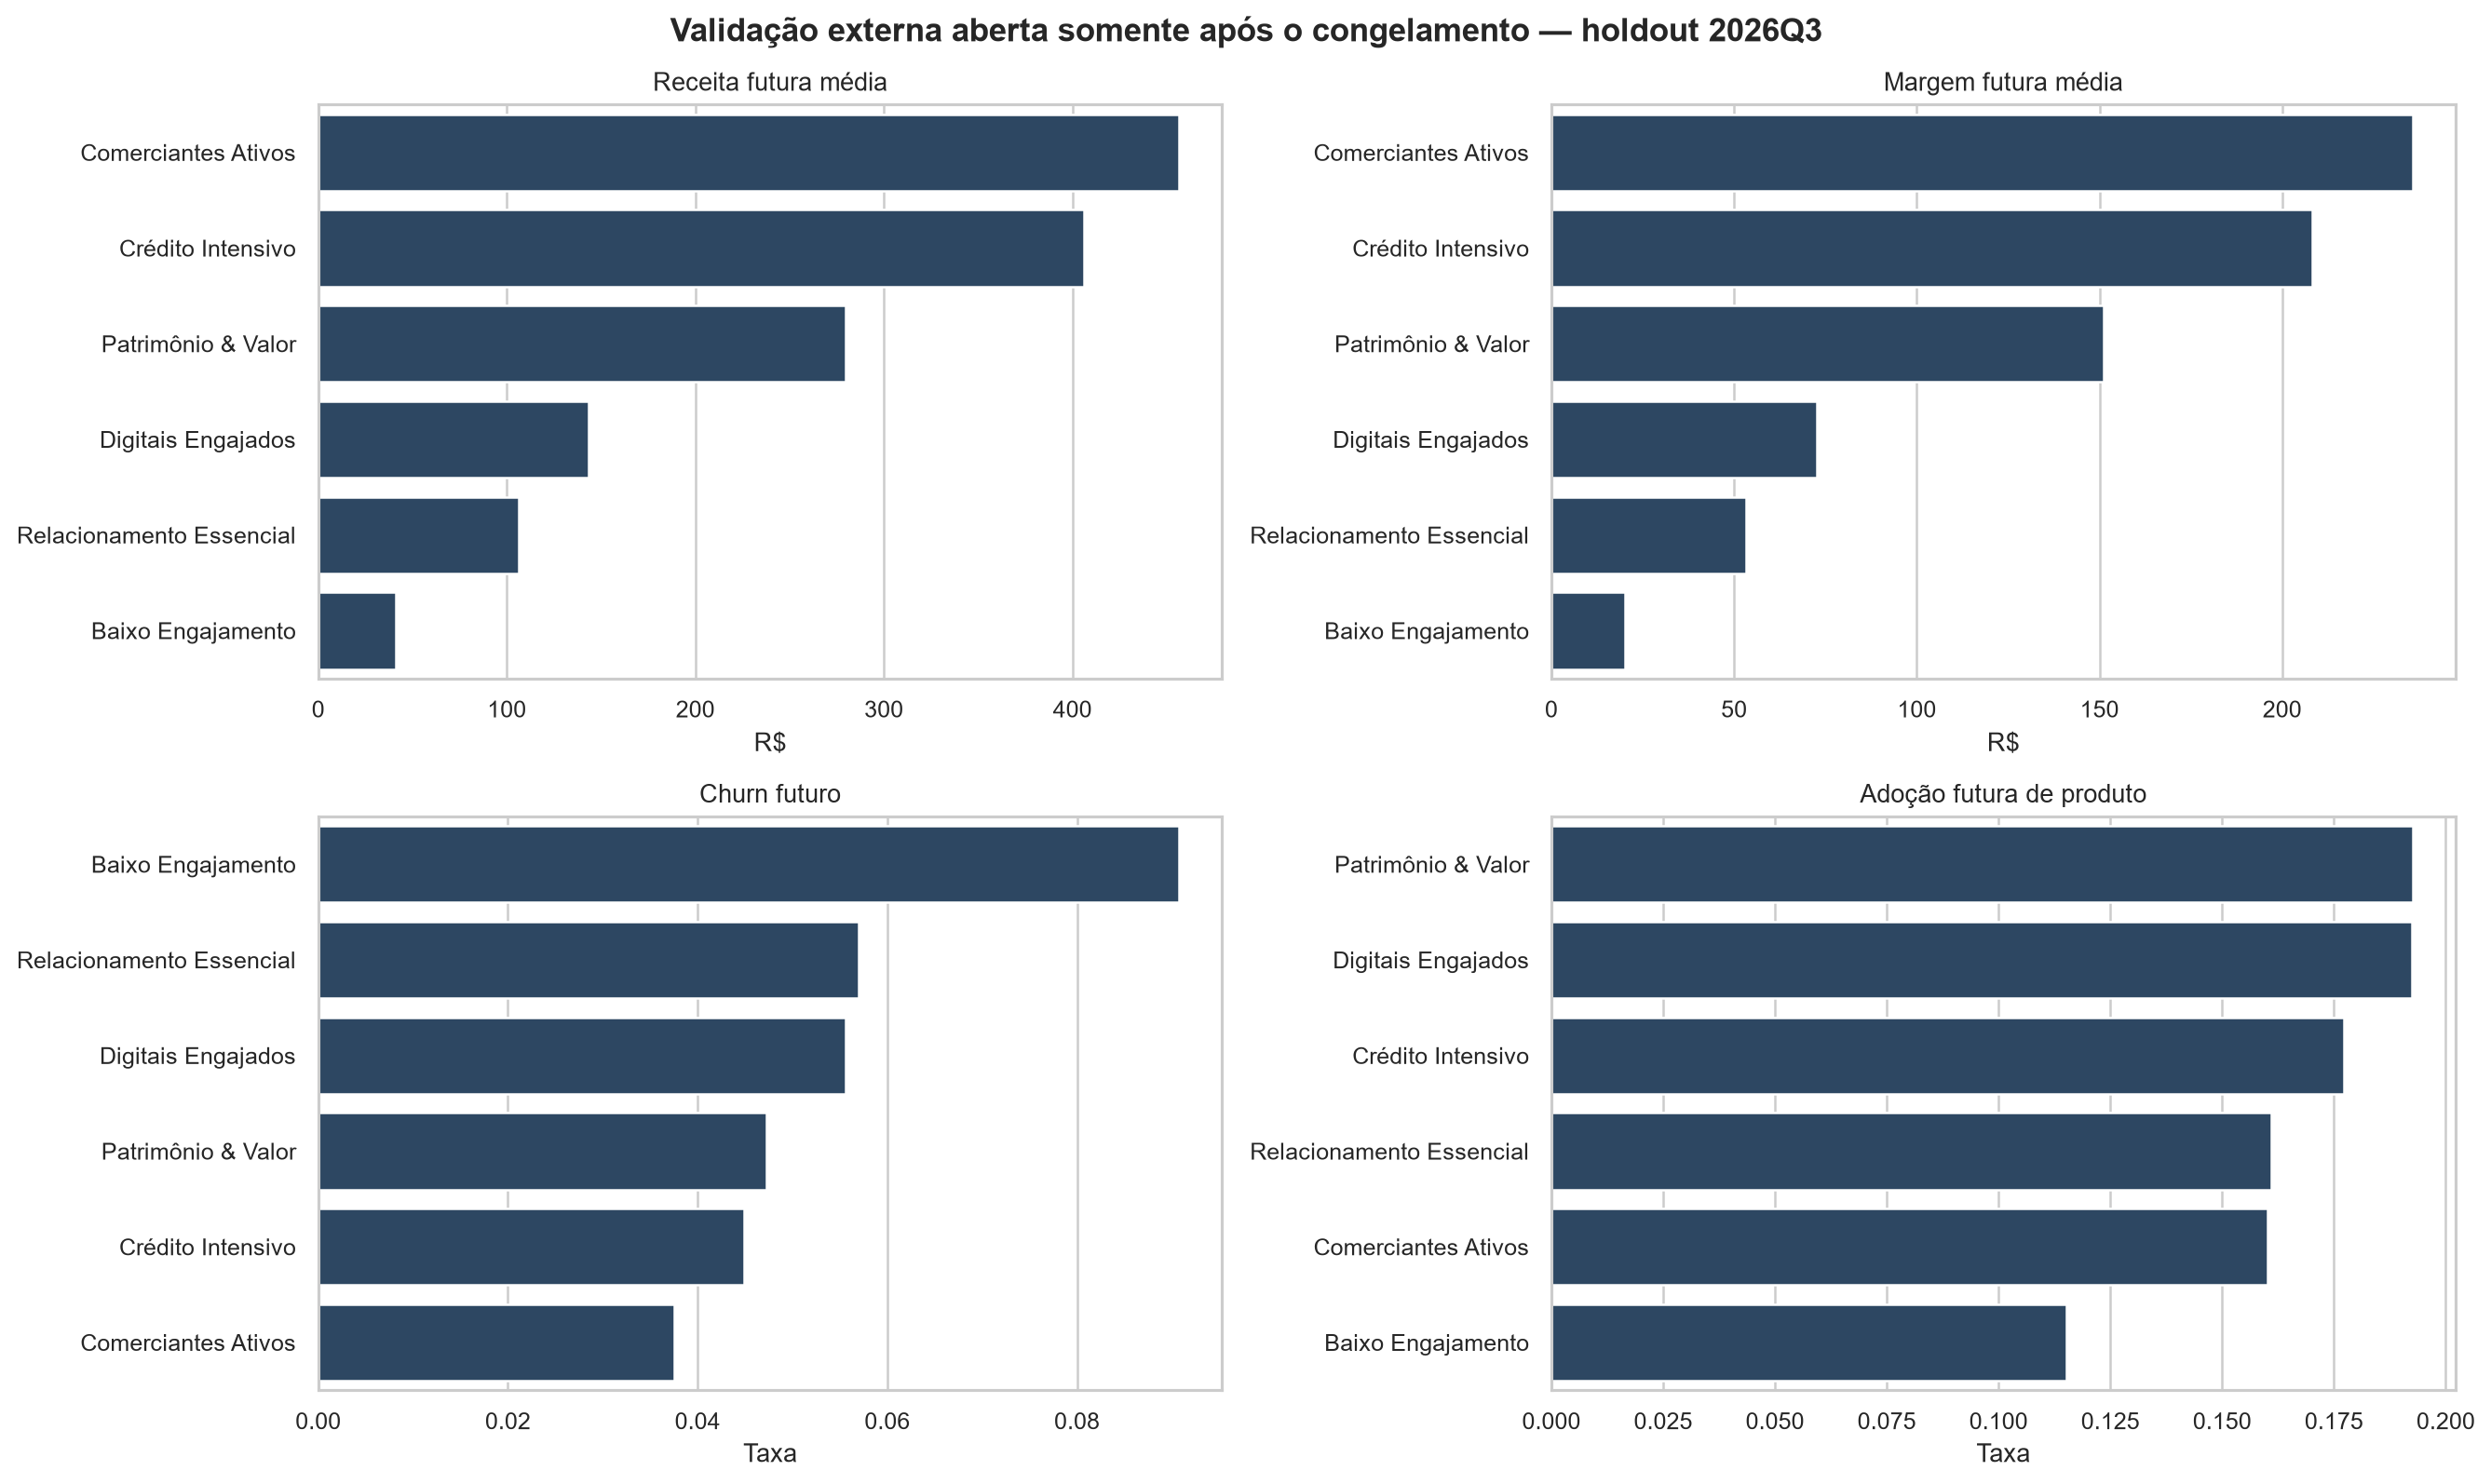

In [6]:
future = pd.read_csv(ROOT/'outputs/tables/future_outcome_validation_by_segment.csv')
display(future[future.snapshot_quarter.eq('2026Q3')][['segment_name','customers','revenue_next_90d','margin_next_90d','churn_next_90d','product_adoption_next_90d']])
display(Image(filename=str(ROOT/'outputs/figures/07_future_outcome_validation.png')))

## 7. Tradução em ação e limites causais

Os playbooks são hipóteses operacionalizáveis com guardrails. Segmentos não demonstram que a ação sugerida causa melhora; campanhas devem ser randomizadas dentro de cada segmento e avaliadas por efeito incremental.

In [7]:
display(pd.read_csv(ROOT/'outputs/tables/segment_actionability_playbook.csv'))

,segment_name,q1_share,business_objective,action_hypothesis,primary_guardrail,q3_revenue_next_90d,q3_churn_next_90d,q3_product_adoption_next_90d,causal_status
0,Digitais Engajados,0.393623,Cross-sell digital,Next-best-product em canais próprios,Fadiga e opt-out,143.429410,0.055564,0.192495,Hypothesis requiring controlled experiment
1,Baixo Engajamento,0.276810,Retenção diagnóstica,Testar reativação de baixo custo antes de ince...,ROI incremental e sleeping dogs,41.026329,0.090772,0.115129,Hypothesis requiring controlled experiment
2,Crédito Intensivo,0.119267,Crédito responsável,Limite e parcelamento com elegibilidade e risco,Inadimplência e sobre-endividamento,405.945290,0.044908,0.177153,Hypothesis requiring controlled experiment
3,Patrimônio & Valor,0.106567,Proteção e profundidade,"Assessoria, investimentos e benefícios de rela...",Evasão de saldo e churn,279.447563,0.047274,0.192514,Hypothesis requiring controlled experiment
4,Relacionamento Essencial,0.076083,Educação e ativação,Jornadas simples para aumentar uso e profundidade,Custo de contato,106.335330,0.057001,0.160879,Hypothesis requiring controlled experiment
5,Comerciantes Ativos,0.027650,Relacionamento e adquirência,"Ofertas de POS, capital de giro e serviços tra...",Margem e reclamações,456.596393,0.037504,0.160110,Hypothesis requiring controlled experiment


## 8. Monitoramento e conclusão executiva

Monitorar participação, distância a centroides, missing, estabilidade de perfis, outcomes externos, custo de contato e guardrails. Recalibrar a taxonomia somente com evidência de drift material e benefício operacional.

**Conclusão obrigatória:** O melhor clustering não é necessariamente aquele com maior Silhouette. A solução final deve equilibrar separação matemática, estabilidade temporal, interpretabilidade, diferenciação futura e capacidade de gerar ações de negócio.

## 9. Reprodução completa

Para regenerar todos os artefatos a partir da base raw, execute na raiz do repositório: `python -m src.run_case`. A implementação reutilizável está em `src/`, e todos os parâmetros críticos são congelados e versionados.